# Customer Clustering

The objective of this notebook is to identify distinct customer segments using the principal components generated in the PCA stage.

K-Means clustering will initially be evaluated across multiple values of K. Internal validation metrics will be used to determine the most appropriate number of customer segments before interpreting the characteristics of each segment.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

df_pca = pd.read_excel("../data/OmniRetail_PCA.xlsx")

print("Shape:", df_pca.shape)
df_pca.head()

Shape: (5200, 7)


,Customer_ID,PC1,PC2,PC3,PC4,PC5,PC6
0,C104801,-2.584474,-1.405557,0.501716,-0.734256,-0.053480,0.827908
1,C104444,-1.730177,2.069721,-0.643950,0.816228,-1.064037,0.376115
2,C103868,-1.233990,0.597653,-0.170696,0.586941,-0.172576,0.295104
3,C101648,-1.211256,1.277548,0.219000,0.752943,0.652578,-0.976701
4,C101693,2.985212,-1.579532,-0.033884,-0.560353,0.013543,0.107138


In [2]:
pca_features = [f"PC{i}" for i in range(1, 7)]

X_cluster = df_pca[pca_features].copy()

print("Clustering features:", pca_features)
print("Shape:", X_cluster.shape)

Clustering features: ['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']
Shape: (5200, 6)


In [3]:
results = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = kmeans.fit_predict(X_cluster)

    results.append({
        "K": k,
        "Inertia": kmeans.inertia_,
        "Silhouette": silhouette_score(X_cluster, labels),
        "Calinski_Harabasz": calinski_harabasz_score(X_cluster, labels),
        "Davies_Bouldin": davies_bouldin_score(X_cluster, labels)
    })

cluster_results = pd.DataFrame(results)

cluster_results.round(3)

,K,Inertia,Silhouette,Calinski_Harabasz,Davies_Bouldin
0,2,27556.000,0.457,4688.664,0.951
1,3,21723.923,0.448,3670.729,0.865
2,4,16710.151,0.403,3700.468,1.009
3,5,14964.780,0.361,3249.925,1.137
4,6,13812.653,0.362,2902.910,1.004
5,7,12278.145,0.367,2829.075,0.940
6,8,11828.667,0.338,2544.763,1.112


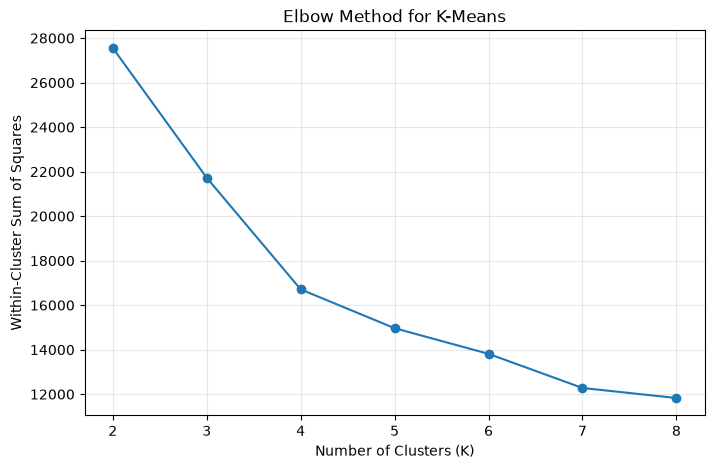

In [4]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results["K"],
    cluster_results["Inertia"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.title("Elbow Method for K-Means")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.show()

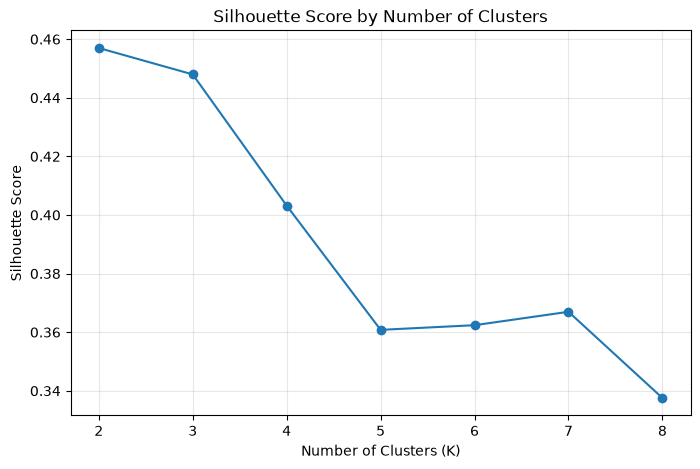

In [5]:
plt.figure(figsize=(8, 5))

plt.plot(
    cluster_results["K"],
    cluster_results["Silhouette"],
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(range(2, 9))
plt.grid(alpha=0.3)

plt.show()

Seeing the above k = 2 and k = 3 are suitable number of clusters. k=2 is the most proven by data but k = 3 gives us more business interpretation.

Testing first for k = 2

In [6]:
cluster_size_results = []

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_cluster)

    counts = pd.Series(labels).value_counts().sort_index()

    for cluster_id, count in counts.items():
        cluster_size_results.append({
            "K": k,
            "Cluster": f"Cluster {cluster_id}",
            "Customers": count,
            "Percentage": round(count / len(X_cluster) * 100, 2)
        })

cluster_size_df = pd.DataFrame(cluster_size_results)

cluster_size_df

,K,Cluster,Customers,Percentage
0,2,Cluster 0,3030,58.27
1,2,Cluster 1,2170,41.73
2,3,Cluster 0,3028,58.23
3,3,Cluster 1,1076,20.69
4,3,Cluster 2,1096,21.08


In [7]:
df_clean = pd.read_excel(
    "../data/OmniRetail_Cleaned.xlsx"
)

cluster_labels = df_pca[["Customer_ID"]].copy()

for k in [2, 3]:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    cluster_labels[f"Cluster_K{k}"] = model.fit_predict(
        X_cluster
    )

clustered_df = df_clean.merge(
    cluster_labels,
    on="Customer_ID",
    how="left",
    validate="one_to_one"
)

clustered_df.head()

,Customer_ID,Snapshot_Date,Region,City_Tier,Age,Annual_Income_000,Annual_Spend_000,Store_Visits_Year,Online_Orders_Year,Avg_Basket_Value,...,Satisfaction_Score,Complaints_Year,Loyalty_Points,Membership_Tier,Preferred_Category,Acquisition_Channel,Signup_Date,Last_Purchase_Date,Cluster_K2,Cluster_K3
0,C104801,2026-08-01,South,Tier 2,43,671.4,121.6,6,20,2480.1,...,6.1,3,1835,Silver,Home,Store Walk-in,2021-07-04,2026-07-18,0,0
1,C104444,2026-08-01,West,Tier 2,18,587.3,241.3,2,36,2498.6,...,8.7,1,3711,Basic,Electronics,Marketplace,2023-09-02,2026-07-23,0,0
2,C103868,2026-08-01,North,Tier 2,33,824.9,210.7,14,29,2341.3,...,7.8,2,3871,Basic,Sports,Search Ads,2024-01-02,2026-07-26,0,0
3,C101648,2026-08-01,West,Tier 2,23,1116.1,233.6,23,27,3554.9,...,7.8,3,3085,Basic,Electronics,Store Walk-in,2025-10-01,2026-07-29,0,0
4,C101693,2026-08-01,South,Tier 3,64,1226.5,458.0,29,4,4258.2,...,7.4,1,6932,Silver,Beauty,Referral,2019-11-04,2026-07-05,1,2


In [8]:
profile_cols = [
    "Annual_Income_000",
    "Annual_Spend_000",
    "Avg_Basket_Value",
    "Loyalty_Points",
    "Satisfaction_Score",
    "Online_Orders_Year",
    "Store_Visits_Year",
    "Complaints_Year",
    "Online_Purchase_Pct",
    "Promo_Purchase_Pct",
    "Age"
]

for k in [2, 3]:

    print(f"\n===== CLUSTER PROFILES: K={k} =====")

    display(
        clustered_df.groupby(f"Cluster_K{k}")[profile_cols]
        .mean()
        .round(2)
    )


===== CLUSTER PROFILES: K=2 =====


,Annual_Income_000,Annual_Spend_000,Avg_Basket_Value,Loyalty_Points,Satisfaction_Score,Online_Orders_Year,Store_Visits_Year,Complaints_Year,Online_Purchase_Pct,Promo_Purchase_Pct,Age
Cluster_K2,,,,,,,,,,,
0,749.91,214.89,2353.51,3234.69,7.00,19.30,11.79,2.31,57.82,50.37,32.16
1,1371.43,425.90,4882.30,6395.28,8.16,14.56,29.45,1.09,33.44,18.37,49.09



===== CLUSTER PROFILES: K=3 =====


,Annual_Income_000,Annual_Spend_000,Avg_Basket_Value,Loyalty_Points,Satisfaction_Score,Online_Orders_Year,Store_Visits_Year,Complaints_Year,Online_Purchase_Pct,Promo_Purchase_Pct,Age
Cluster_K3,,,,,,,,,,,
0,748.56,214.92,2353.96,3235.02,7.00,19.29,11.79,2.31,57.82,50.37,32.14
1,1661.14,523.65,6155.74,6772.13,8.34,21.80,23.75,1.04,47.59,16.64,43.61
2,1089.60,329.47,3626.23,6018.65,7.98,7.48,35.02,1.15,19.59,20.12,54.51


### Final Cluster Selection

The three-cluster solution was selected for further analysis because it provides more actionable customer differentiation than the two-cluster solution. The resulting clusters exhibit distinct patterns in annual spending, basket value, satisfaction, online purchasing, promotional dependence and store engagement.

Although the two-cluster solution achieved slightly better Silhouette and Calinski–Harabasz scores, the three-cluster solution offers greater business interpretability. The selected model will therefore be evaluated further through segment profiling and validation before final recommendations are developed.

In [9]:
final_kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

clustered_df["Customer_Segment"] = final_kmeans.fit_predict(
    X_cluster
)

clustered_df["Customer_Segment"] = (
    clustered_df["Customer_Segment"] + 1
)

clustered_df["Customer_Segment"].value_counts().sort_index()

Customer_Segment
1    3028
2    1076
3    1096
Name: count, dtype: int64

In [10]:
for col in [
    "Membership_Tier",
    "City_Tier",
    "Acquisition_Channel"
]:
    print(f"\n===== {col} BY CUSTOMER SEGMENT =====")

    display(
        pd.crosstab(
            clustered_df["Customer_Segment"],
            clustered_df[col],
            normalize="index"
        ).mul(100).round(1)
    )


===== Membership_Tier BY CUSTOMER SEGMENT =====


Membership_Tier,Basic,Gold,Platinum,Silver,Unknown
Customer_Segment,,,,,
1,66.6,2.2,0.2,29.9,1.2
2,1.0,48.0,31.5,18.5,0.9
3,11.4,27.9,0.5,59.5,0.7



===== City_Tier BY CUSTOMER SEGMENT =====


City_Tier,Tier 1,Tier 2,Tier 3
Customer_Segment,,,
1,47.7,36.6,15.7
2,45.8,35.5,18.7
3,45.3,39.9,14.8



===== Acquisition_Channel BY CUSTOMER SEGMENT =====


Acquisition_Channel,Marketplace,Organic,Referral,Search Ads,Social Media,Store Walk-in
Customer_Segment,,,,,,
1,12.5,19.2,13.6,17.9,17.3,19.4
2,12.4,19.8,12.5,17.8,18.3,19.2
3,11.4,19.2,15.1,18.5,16.7,19.2


Categorical Segment Validation: Categorical variables excluded from the clustering inputs are compared across the resulting segments. Chi-square tests and Cramér's V are used to assess whether segment membership is associated with membership tier, city tier, and acquisition channel.

In [11]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd

categorical_cols = [
    "Membership_Tier",
    "City_Tier",
    "Acquisition_Channel"
]

association_results = []

for col in categorical_cols:

    contingency_table = pd.crosstab(
        clustered_df["Customer_Segment"],
        clustered_df[col]
    )

    chi2, p_value, dof, expected = chi2_contingency(
        contingency_table
    )

    n = contingency_table.to_numpy().sum()
    min_dimension = min(contingency_table.shape) - 1

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    association_results.append({
        "Variable": col,
        "Chi_Square": chi2,
        "Degrees_of_Freedom": dof,
        "P_Value": p_value,
        "Cramers_V": cramers_v
    })

association_df = pd.DataFrame(association_results)

association_df.round(4)

,Variable,Chi_Square,Degrees_of_Freedom,P_Value,Cramers_V
0,Membership_Tier,3746.4177,8,0.0000,0.6002
1,City_Tier,10.3388,4,0.0351,0.0315
2,Acquisition_Channel,4.6275,10,0.9146,0.0211


### Categorical Segment Validation

Chi-square tests and Cramér's V were used to examine the association between customer segment assignment and three categorical variables.

- **Membership Tier:** A strong association was observed (Cramér's V = 0.6002, p < 0.001), indicating substantial differences in membership composition across the three segments.
- **City Tier:** The association was negligible (Cramér's V = 0.0315, p = 0.0351), suggesting that city tier offers little practical differentiation between segments. This result is also not significant at the 5% level after a Bonferroni correction for the three tests.
- **Acquisition Channel:** No statistically significant association was observed (Cramér's V = 0.0211, p = 0.9146), indicating broadly similar acquisition-channel distributions across segments.

Overall, membership tier is the strongest categorical differentiator of the three customer segments, whereas city tier and acquisition channel contribute little additional distinction.

Overall Silhouette Score: 0.448
                   mean  median    min    max
Customer_Segment                             
1                 0.450   0.463 -0.026  0.614
2                 0.419   0.443  0.030  0.577
3                 0.470   0.490  0.022  0.617


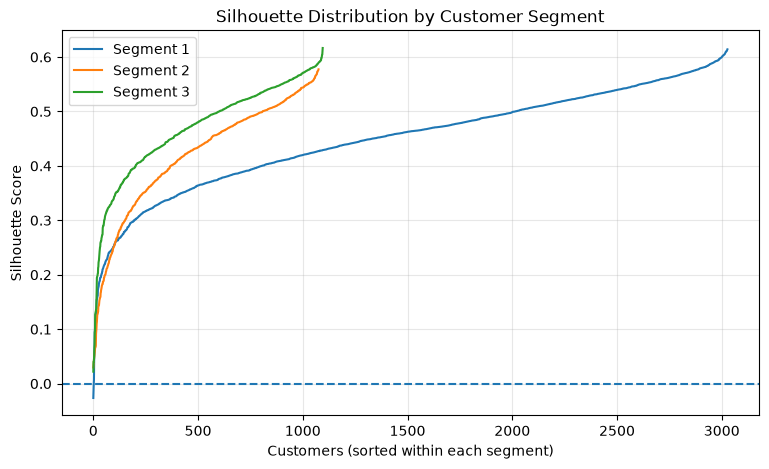

In [12]:
from sklearn.metrics import silhouette_score, silhouette_samples

final_labels = clustered_df["Customer_Segment"] - 1

overall_silhouette = silhouette_score(
    X_cluster,
    final_labels
)

print("Overall Silhouette Score:", round(overall_silhouette, 4))

silhouette_values = silhouette_samples(
    X_cluster,
    final_labels
)

silhouette_df = pd.DataFrame({
    "Customer_Segment": clustered_df["Customer_Segment"].values,
    "Silhouette_Score": silhouette_values
})

cluster_silhouette = (
    silhouette_df.groupby("Customer_Segment")["Silhouette_Score"]
    .agg(["mean", "median", "min", "max"])
    .round(3)
)

print(cluster_silhouette)

plt.figure(figsize=(9, 5))

for segment in sorted(silhouette_df["Customer_Segment"].unique()):
    values = silhouette_df.loc[
        silhouette_df["Customer_Segment"] == segment,
        "Silhouette_Score"
    ].sort_values().reset_index(drop=True)

    plt.plot(
        values,
        label=f"Segment {segment}"
    )

plt.axhline(0, linestyle="--")
plt.xlabel("Customers (sorted within each segment)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Distribution by Customer Segment")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [13]:
segment_profile = clustered_df.groupby("Customer_Segment").agg(
    Customer_Count=("Customer_ID", "count"),
    Avg_Age=("Age", "mean"),
    Avg_Income=("Annual_Income_000", "mean"),
    Avg_Spend=("Annual_Spend_000", "mean"),
    Avg_Basket_Value=("Avg_Basket_Value", "mean"),
    Avg_Loyalty_Points=("Loyalty_Points", "mean"),
    Avg_Satisfaction=("Satisfaction_Score", "mean"),
    Avg_Online_Orders=("Online_Orders_Year", "mean"),
    Avg_Store_Visits=("Store_Visits_Year", "mean"),
    Avg_Complaints=("Complaints_Year", "mean"),
    Avg_Online_Purchase_Pct=("Online_Purchase_Pct", "mean"),
    Avg_Promo_Purchase_Pct=("Promo_Purchase_Pct", "mean")
).round(2)

segment_profile["Customer_Percentage"] = (
    segment_profile["Customer_Count"] /
    len(clustered_df) * 100
).round(2)

segment_profile

,Customer_Count,Avg_Age,Avg_Income,Avg_Spend,Avg_Basket_Value,Avg_Loyalty_Points,Avg_Satisfaction,Avg_Online_Orders,Avg_Store_Visits,Avg_Complaints,Avg_Online_Purchase_Pct,Avg_Promo_Purchase_Pct,Customer_Percentage
Customer_Segment,,,,,,,,,,,,,
1,3028,32.14,748.56,214.92,2353.96,3235.02,7.00,19.29,11.79,2.31,57.82,50.37,58.23
2,1076,43.61,1661.14,523.65,6155.74,6772.13,8.34,21.80,23.75,1.04,47.59,16.64,20.69
3,1096,54.51,1089.60,329.47,3626.23,6018.65,7.98,7.48,35.02,1.15,19.59,20.12,21.08


### Final Clustering Validation Results

The three-cluster K-Means solution achieved an overall silhouette score of 0.448, indicating reasonably defined customer groups with some expected overlap.

Segment 3 recorded the highest mean silhouette score (0.470), followed by Segment 1 (0.450) and Segment 2 (0.419). Although Segment 2 has comparatively weaker separation, all three segments have positive average silhouette scores.

The three-cluster solution is retained because it provides meaningful differentiation in customer spending, basket value, satisfaction, online purchasing and promotional dependence. Its business interpretability, combined with acceptable cluster separation, supports its use for subsequent customer profiling and strategic recommendations.

## Final Segment Summary

The selected K-Means model identifies three customer segments with distinct spending, purchasing and engagement patterns.

- **Segment 1: Digital, Promotion-Dependent Customers** — The largest segment, with relatively low spending, high online purchasing and high promotional dependence. The key opportunity is to improve satisfaction and encourage sustainable repeat spending.
- **Segment 2: High-Value, Omnichannel Customers** — The highest-spending and most satisfied segment, with strong loyalty and substantial online engagement. Retention and profitable relationship development are the primary priorities.
- **Segment 3: Store-Oriented, High-Value Customers** — A comparatively older segment with high store-visit frequency, moderate-high spending and low online purchase share. The opportunity is to strengthen store-led loyalty and explore convenient digital integration.

The three-cluster solution is retained because it combines reasonable internal validation with meaningful behavioral and membership differences. These segments provide the basis for targeted business recommendations and dashboard reporting.

In [14]:
clustered_df.to_excel(
    "../data/OmniRetail_Customer_Segments.xlsx",
    index=False
)

print("Export complete:", clustered_df.shape)

Export complete: (5200, 25)


## One question to ask is, did PCA actually help produce better customer segments, or did it remove some useful distincitons?

In [15]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score
)
import pandas as pd
import numpy as np

# Select the same 12 features used for PCA
pca_features = [
    "Age",
    "Annual_Income_000",
    "Annual_Spend_000",
    "Store_Visits_Year",
    "Online_Orders_Year",
    "Complaints_Year",
    "Loyalty_Points",
    "Satisfaction_Score",
    "Online_Purchase_Pct",
    "Promo_Purchase_Pct",
    "Avg_Basket_Value",
    "Tenure_Months"
]

# Standardize original features
X_original = df_clean[pca_features].copy()

scaler_original = StandardScaler()
X_original_scaled = scaler_original.fit_transform(X_original)

# K-Means on standardized original features
kmeans_original = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

labels_original = kmeans_original.fit_predict(
    X_original_scaled
)

# Existing PCA-based labels (convert segments 1–3 back to 0–2)
labels_pca = clustered_df["Customer_Segment"].to_numpy() - 1

# Compare metrics
comparison = pd.DataFrame([
    {
        "Method": "PCA + K-Means",
        "Silhouette": silhouette_score(X_cluster, labels_pca),
        "Davies_Bouldin": davies_bouldin_score(X_cluster, labels_pca),
        "Calinski_Harabasz": calinski_harabasz_score(X_cluster, labels_pca)
    },
    {
        "Method": "Original Features + K-Means",
        "Silhouette": silhouette_score(X_original_scaled, labels_original),
        "Davies_Bouldin": davies_bouldin_score(X_original_scaled, labels_original),
        "Calinski_Harabasz": calinski_harabasz_score(X_original_scaled, labels_original)
    }
])

comparison.round(3)

,Method,Silhouette,Davies_Bouldin,Calinski_Harabasz
0,PCA + K-Means,0.448,0.865,3670.729
1,Original Features + K-Means,0.374,1.150,2526.668


In [16]:
cluster_sizes = pd.DataFrame({
    "PCA_Cluster": pd.Series(labels_pca).value_counts().sort_index(),
    "Original_Cluster": pd.Series(labels_original).value_counts().sort_index()
}).fillna(0).astype(int)

cluster_sizes

,PCA_Cluster,Original_Cluster
0,3028,3029
1,1076,1076
2,1096,1095


In [17]:
profile_cols = [
    "Annual_Income_000",
    "Annual_Spend_000",
    "Avg_Basket_Value",
    "Loyalty_Points",
    "Satisfaction_Score",
    "Online_Orders_Year",
    "Store_Visits_Year",
    "Complaints_Year",
    "Online_Purchase_Pct",
    "Promo_Purchase_Pct",
    "Age"
]

original_clustered = df_clean.copy()
original_clustered["Cluster"] = labels_original

original_profile = original_clustered.groupby("Cluster")[
    profile_cols
].mean().round(2)

original_profile

,Annual_Income_000,Annual_Spend_000,Avg_Basket_Value,Loyalty_Points,Satisfaction_Score,Online_Orders_Year,Store_Visits_Year,Complaints_Year,Online_Purchase_Pct,Promo_Purchase_Pct,Age
Cluster,,,,,,,,,,,
0,748.66,214.96,2354.02,3235.21,7.00,19.29,11.79,2.31,57.82,50.36,32.15
1,1661.14,523.65,6155.74,6772.13,8.34,21.80,23.75,1.04,47.59,16.64,43.61
2,1089.65,329.47,3627.22,6020.65,7.98,7.46,35.04,1.15,19.56,20.11,54.49


In [18]:
from sklearn.metrics import adjusted_rand_score

ari = adjusted_rand_score(
    labels_pca,
    labels_original
)

print("Adjusted Rand Index:", round(ari, 4))

Adjusted Rand Index: 0.9994


### PCA-Based vs. Original-Feature Clustering

K-Means clustering was performed using both the six retained PCA components and the 12 standardized original numerical features, with three clusters and identical random-state and initialization settings.

The PCA-based model achieved a higher Silhouette Score (0.448 vs. 0.374), a lower Davies–Bouldin Index (0.865 vs. 1.150), and a higher Calinski–Harabasz Index (3,670.729 vs. 2,526.668), indicating better separation and compactness according to these internal evaluation metrics.

The Adjusted Rand Index between the two clustering solutions was **0.9994**, demonstrating near-identical customer assignments. The cluster sizes and customer profiles were also virtually unchanged.

**Decision:** Retain PCA-based K-Means as the final model. It provides a lower-dimensional representation, performs better on all three internal evaluation metrics, and preserves the customer segmentation obtained from the original features.

These results support the robustness of the segmentation to the choice of feature representation. They do not, by themselves, establish that three clusters are the uniquely correct solution or that the segments will produce better business outcomes.